In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN



In [76]:
rmsd = pd.read_csv("/home/projects2/pbacu/projects/structureTCR/benchmarkData/data/solvedTemplates_characterization/rmsd.txt", sep='\r', header=None)
df_rmsd = rmsd[0].str.split(expand=True).astype(float)

df = pd.read_csv("/home/projects2/pbacu/projects/structureTCR/benchmarkData/data/solvedTemplates_characterization/parse_output.tsv", sep="\t")
df["pdb_id"] = df["pdbfile"].str.split("/").str[-1].str.split(".").str[0]
print(df.columns)

Index(['pdbfile', 'organism', 'mhc_class', 'sequence', 'chainseq',
       'tcrdock_info', 'torsion', 'd', 'tcr_unit_y', 'tcr_unit_z',
       'tcr_unit_x_is_negative', 'mhc_unit_y', 'mhc_unit_z',
       'mhc_unit_x_is_negative', 'tcr_frame_x_axis', 'tcr_frame_y_axis',
       'tcr_frame_z_axis', 'tcr_frame_origin', 'mhc_frame_x_axis',
       'mhc_frame_y_axis', 'mhc_frame_z_axis', 'mhc_frame_origin', 'pdb_id'],
      dtype='object')


In [ ]:
#set rownames and column names of df_rmsd to pdb_id
df_rmsd.index = df["pdb_id"]
df_rmsd.columns = df["pdb_id"]

/home/projects2/pbacu/utils/Miniconda/envs/af3/lib/python3.12/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
/home/projects2/pbacu/utils/Miniconda/envs/af3/lib/python3.12/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


<Figure size 1000x600 with 0 Axes>

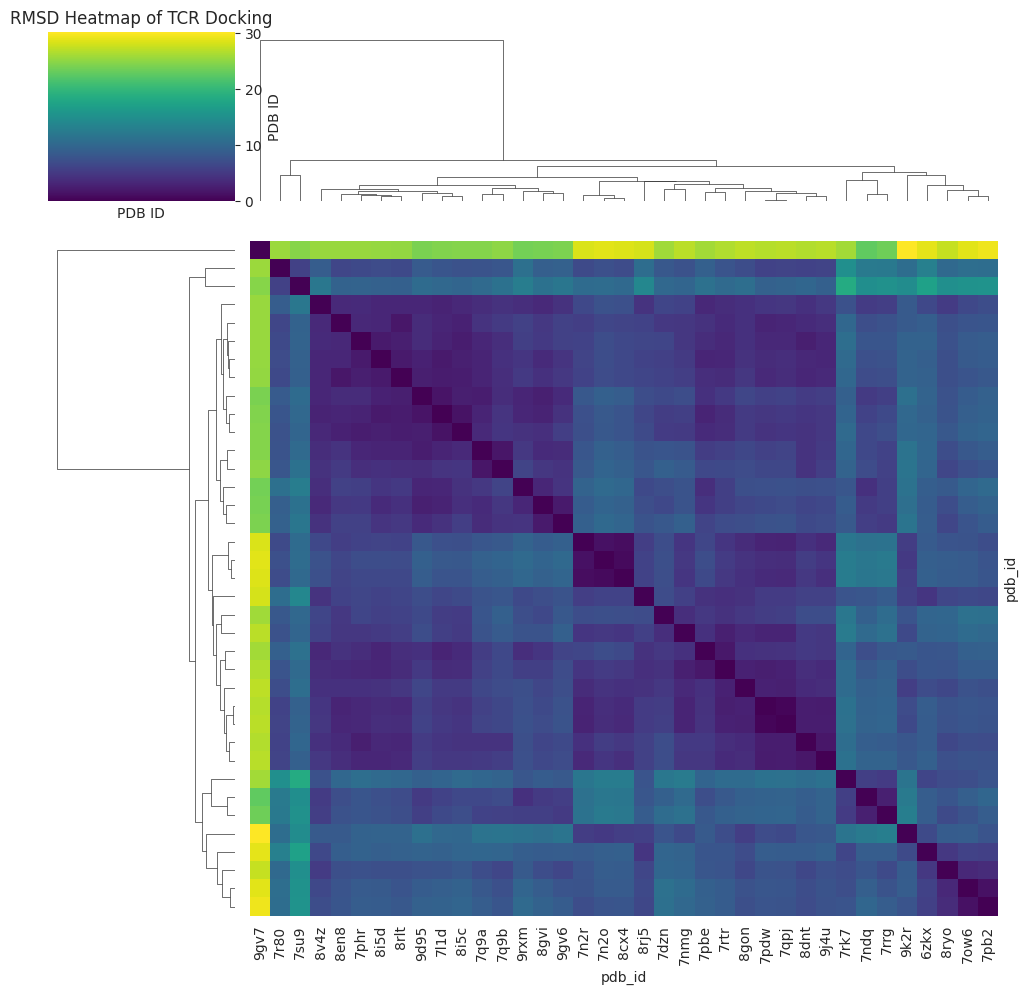

In [94]:
#Cluster the rmsd
plt.figure(figsize=(10, 6))

sns.clustermap(df_rmsd, cmap="viridis", 
               xticklabels=True, yticklabels=False)
plt.title("RMSD Heatmap of TCR Docking")
plt.xlabel("PDB ID")
plt.ylabel("PDB ID")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

/home/projects2/pbacu/utils/Miniconda/envs/af3/lib/python3.12/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
/home/projects2/pbacu/utils/Miniconda/envs/af3/lib/python3.12/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


<Figure size 1000x600 with 0 Axes>

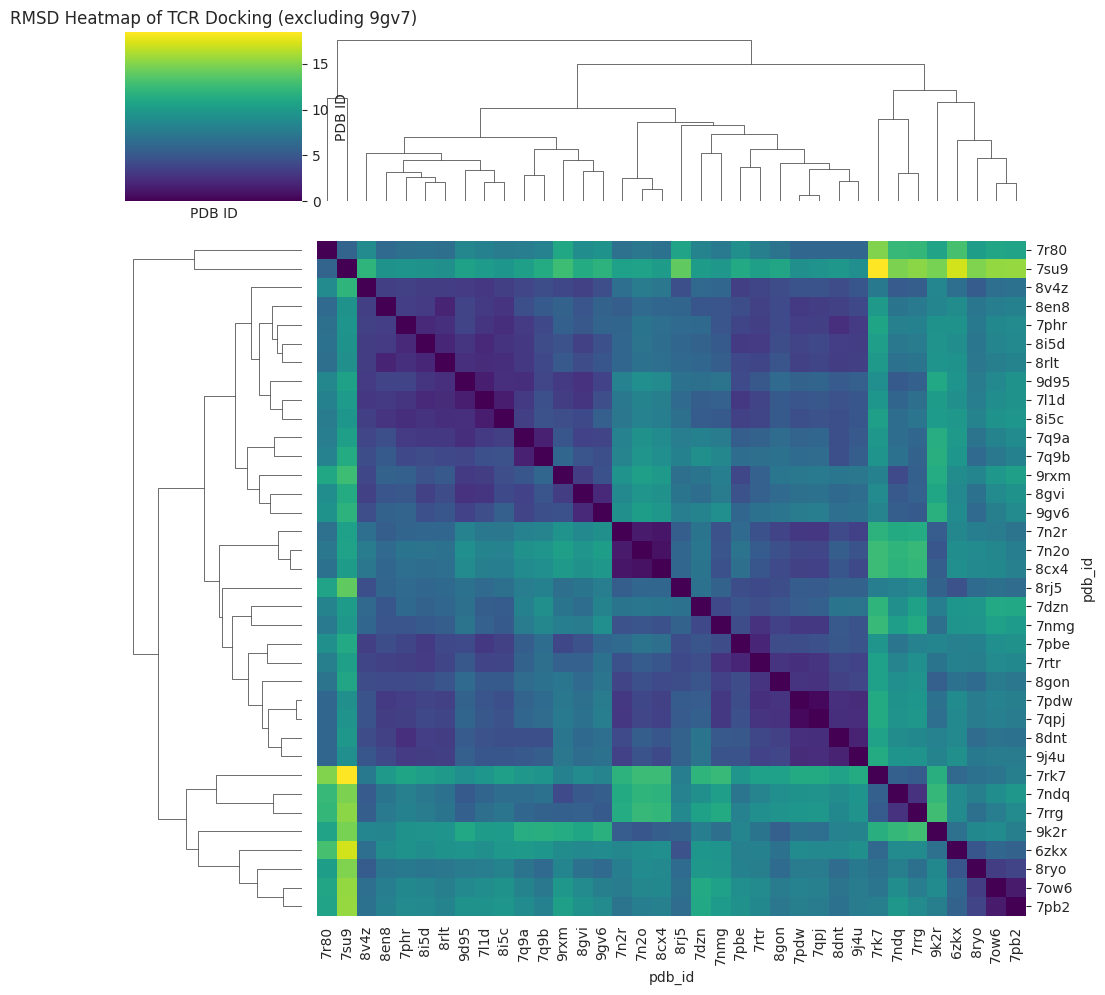

In [93]:
#exclude 9gv7 
df_rmsd_excl = df_rmsd.drop(index="9gv7", columns="9gv7")
#Cluster the rmsd excluding 9gv7
plt.figure(figsize=(10, 6))
sns.clustermap(df_rmsd_excl, cmap="viridis",
               xticklabels=True, yticklabels=True)
plt.title("RMSD Heatmap of TCR Docking (excluding 9gv7)")
plt.xlabel("PDB ID")
plt.ylabel("PDB ID")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

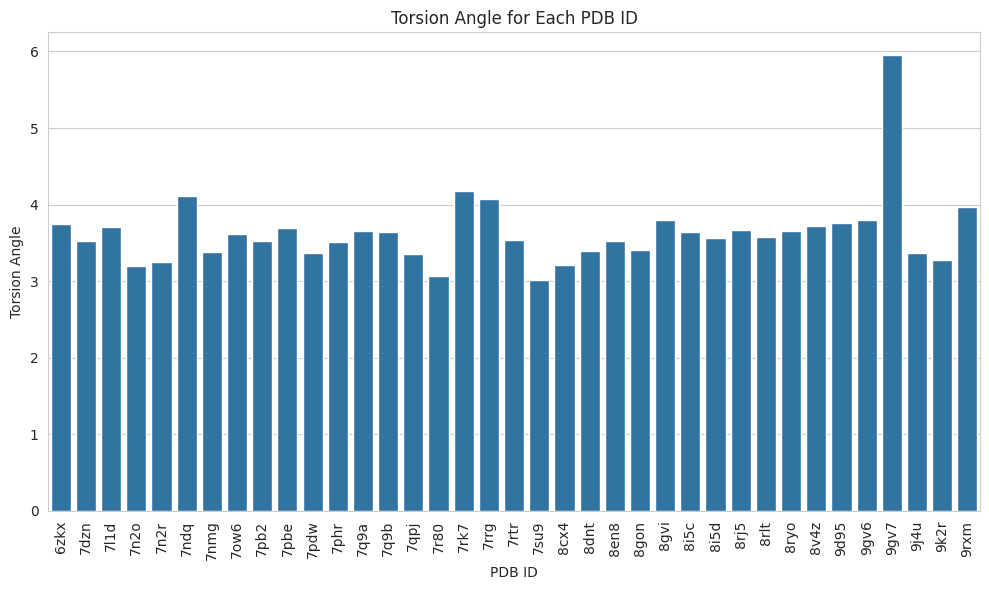

In [11]:
sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))
sns.barplot(x="pdb_id", y="torsion", data=df)
plt.xticks(rotation=90)
plt.title("Torsion Angle for Each PDB ID")
plt.xlabel("PDB ID")
plt.ylabel("Torsion Angle")
plt.tight_layout()
plt.show()

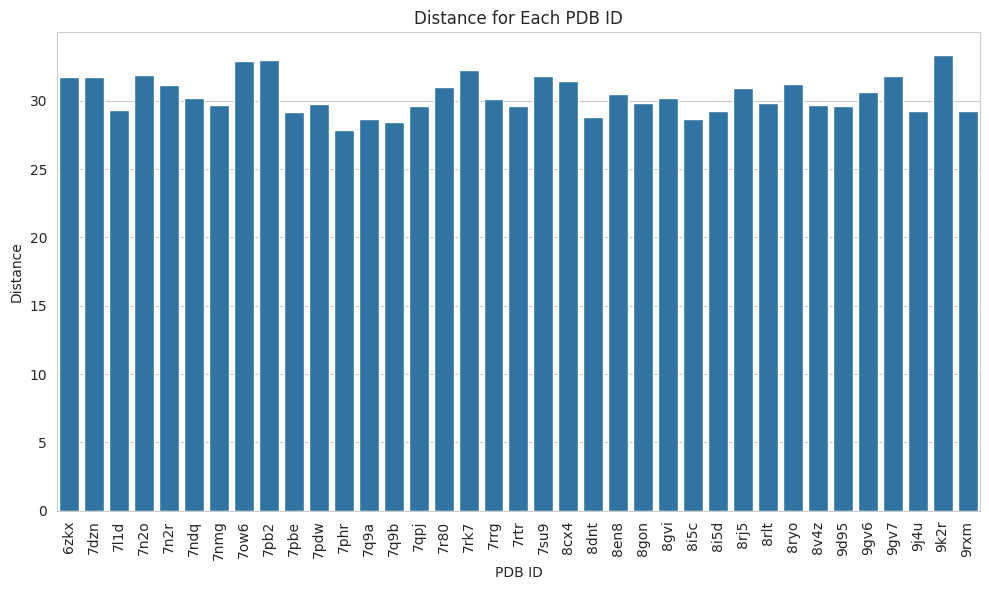

In [14]:
sns.set_style("whitegrid")
plt.figure(figsize=(10, 6))
sns.barplot(x="pdb_id", y="d", data=df)
plt.xticks(rotation=90)
plt.title("Distance for Each PDB ID")
plt.xlabel("PDB ID")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1323064/3066132924.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data=df, x="torsion", y="d",palette="Set1")


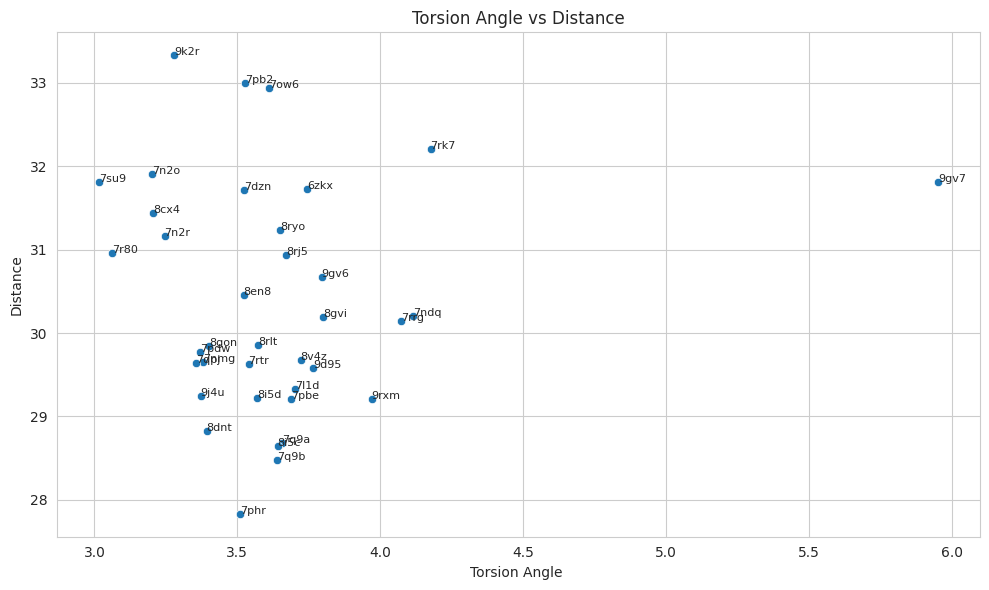

In [62]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="torsion", y="d",palette="Set1")
plt.title("Torsion Angle vs Distance")
plt.xlabel("Torsion Angle ")
plt.ylabel("Distance")
#show pdb_id labels in plot
for i in range(df.shape[0]):
    plt.text(df["torsion"].iloc[i], df["d"].iloc[i], df["pdb_id"].iloc[i], fontsize=8)
plt.tight_layout()
plt.show()

In [20]:
# theta in radians [0, 2π], d is your distance
X = np.column_stack([
    np.sin(df["torsion"]),
    np.cos(df["torsion"]),
    (df["d"] - df["d"].mean()) / df["d"].std()   # z-score normalization
])
X_scaled = StandardScaler().fit_transform(X)

In [56]:
db = DBSCAN(
    eps=0.2,        # key parameter (tune this!)
    min_samples=5   # typical starting point
)
labels = db.fit_predict(X)
df["cluster"] = labels
df["torsion_degrees"] = np.degrees(df["torsion"])

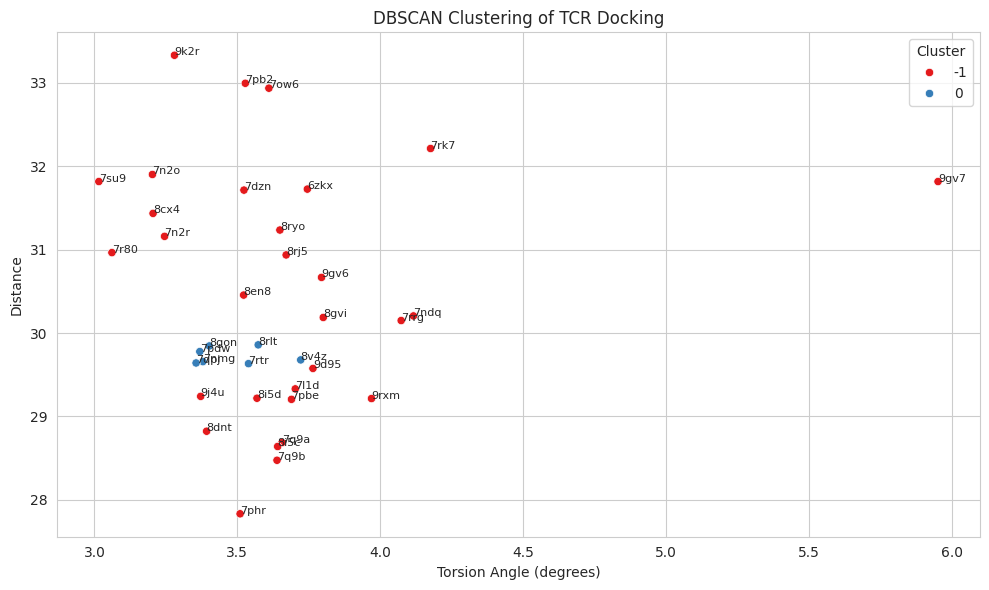

In [57]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="torsion", y="d", hue="cluster", palette="Set1")
plt.title("DBSCAN Clustering of TCR Docking")
plt.xlabel("Torsion Angle (degrees)")
plt.ylabel("Distance")
plt.legend(title="Cluster")
#show pdb_id labels in plot
for i in range(df.shape[0]):
    plt.text(df["torsion"].iloc[i], df["d"].iloc[i], df["pdb_id"].iloc[i], fontsize=8)
plt.tight_layout()
plt.show()